# UTH Computer Vision Coursework — Topic 11: Facial Occlusion & Artifact Detection
## 🔬 Notebook 07: Khám Phá & Kiểm Toán Toàn Diện Bộ Benchmark Đa Phương Pháp (Universal Deepfake Suite)

> **Bối cảnh nghiên cứu & Định danh bộ dữ liệu chuẩn hóa**:
> - **Tên bộ kiểm định**: Universal Multi-Method Deepfake Benchmark Suite (`universal_deepfake_benchmark`)
> - **Quy mô tập chuẩn hóa vàng (Golden Balanced)**: **21.000 ảnh** (Đúng **10.500 Thật vs 10.500 Giả** — Cân bằng $50.00\% - 50.00\%$).
> - **Độ phủ công nghệ**: **35 phương pháp tạo ảnh giả SOTA** thuộc **8 họ công nghệ** lớn (mỗi phương pháp chuẩn đúng **300 ảnh**, trọng số đều $1/35 \approx 2.857\%$).
> - **Quy tắc chọn lọc khoa học**: Đã thanh lọc triệt để 3 phương pháp thiếu hụt mẫu (`heygen` 11 mẫu, `deepfacelab` 25 mẫu, `MidJourney` 187 mẫu) để bảo đảm tính nghiêm ngặt về mặt thống kê ($N=300 \gg 30$).
> - **Cam kết rò rỉ danh tính**: **Zero Identity Leakage** (Độc lập 100% với CelebA-HQ và tập huấn luyện $D_0, D_1, D_2$).

| Chỉ Số Cốt Lõi | Giá Trị Thực Tế Đo Lường |
| :--- | :--- |
| **Tập Dữ Liệu Phân Tách** | `data/benchmarks/universal_deepfake_benchmark/splits/test_coursework_35methods_golden_balanced.csv` |
| **Tổng số lượng mẫu kiểm định** | **21.000 ảnh** (10.500 Real vs 10.500 Fake) |
| **Số lượng phương pháp Fake** | **35 phương pháp** (Mỗi phương pháp đúng 300 mẫu) |
| **Nguồn ảnh thật đối chứng** | FFHQ (Studio độ phân giải cao) & FaceForensics++ (Video Youtube C23 nén thực tế) |
| **Các họ công nghệ kiểm định** | DiT, Latent Diffusion, Face Swapping, Reenactment, GAN, Editing, VAE, DDIM |


In [1]:
# --- [1. CẤU HÌNH MÔI TRƯỜNG & KHỞI TẠO CÁC MODULE THỊ GIÁC] ---
import os
from pathlib import Path
import sys

# Thiết lập đường dẫn gốc workspace uth-cv-coursework
project_root = Path.cwd().resolve()
while project_root.name != "uth-cv-coursework" and project_root.parent != project_root:
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
os.chdir(project_root)

import csv
import json
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import cv2

print(f"[✓] Workspace Root: {project_root}")
print("[✓] Môi trường phân tích dữ liệu thị giác máy tính đã sẵn sàng.")


[✓] Workspace Root: /home/bush/Projects/uth-cv-coursework
[✓] Môi trường phân tích dữ liệu thị giác máy tính đã sẵn sàng.


### 2. Nạp Dữ Liệu Metadata & Xác Thực Tính Cân Bằng Chuẩn Hóa (21.000 Ảnh)

Nạp tập dữ liệu kiểm định chuẩn hóa vàng `test_coursework_35methods_golden_balanced.csv` và kiểm chứng các bất biến về nhãn:


In [2]:
# --- [2. NẠP VÀ KIỂM CHỨNG TẬP DỮ LIỆU BENCHMARK CHUẨN HÓA] ---
golden_csv = Path("data/benchmarks/universal_deepfake_benchmark/splits/test_coursework_35methods_golden_balanced.csv")

with open(golden_csv, "r", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

total_samples = len(rows)
fakes = [r for r in rows if r['label'] == '1']
reals = [r for r in rows if r['label'] == '0']
method_counts = Counter(r['method'] for r in fakes)
real_sources = Counter(r['source'] for r in reals)

print("=== BẢNG KIỂM TOÁN TẬP BENCHMARK CHUẨN HÓA (GOLDEN 21K SUITE) ===")
print(f"[*] Tổng số lượng ảnh kiểm định : {total_samples:,} ảnh")
print(f"    - Ảnh Thật (Real - Label 0)  : {len(reals):,} ảnh ({len(reals)/total_samples*100:.2f}%)")
print(f"    - Ảnh Giả  (Fake - Label 1)  : {len(fakes):,} ảnh ({len(fakes)/total_samples*100:.2f}%)")
print(f"[*] Số lượng phương pháp Fake    : {len(method_counts)} phương pháp")
print(f"[*] Số mẫu mỗi phương pháp Fake  : đúng {set(method_counts.values()).pop()} mẫu/method (đồng đều 100%)")
print(f"[*] Phân bố nguồn ảnh thật đối chứng:")
for src, cnt in real_sources.most_common():
    print(f"    - {src:15s}: {cnt:,} ảnh ({cnt/len(reals)*100:.1f}%)")


=== BẢNG KIỂM TOÁN TẬP BENCHMARK CHUẨN HÓA (GOLDEN 21K SUITE) ===
[*] Tổng số lượng ảnh kiểm định : 21,000 ảnh
    - Ảnh Thật (Real - Label 0)  : 10,500 ảnh (50.00%)
    - Ảnh Giả  (Fake - Label 1)  : 10,500 ảnh (50.00%)
[*] Số lượng phương pháp Fake    : 35 phương pháp
[*] Số mẫu mỗi phương pháp Fake  : đúng 300 mẫu/method (đồng đều 100%)
[*] Phân bố nguồn ảnh thật đối chứng:
    - ffhq_real      : 8,629 ảnh (82.2%)
    - ff++_real      : 1,671 ảnh (15.9%)
    - test_data_v3   : 200 ảnh (1.9%)


### 3. Phân Bố Theo 8 Họ Công Nghệ & Ảnh Thật Đối Chứng (Technology Taxonomy)

Toàn bộ 21.000 ảnh mẫu được phân bổ qua 8 nhánh công nghệ chính, đối trọng với 50% ảnh thật:
- **Real Faces**: 10.500 ảnh ($50.00\%$)
- **Reenactment & Talking Head**: 3.300 ảnh (11 phương pháp $\times$ 300)
- **Face Swapping**: 3.000 ảnh (10 phương pháp $\times$ 300)
- **GAN Architectures**: 1.500 ảnh (5 phương pháp $\times$ 300)
- **Diffusion Transformers (DiT)**: 1.200 ảnh (4 phương pháp $\times$ 300)
- **GAN Inversion & Editing**: 600 ảnh (2 phương pháp $\times$ 300)
- **Latent Diffusion (SD 2.1)**: 300 ảnh
- **Diffusion Baselines (DDIM)**: 300 ảnh
- **AutoEncoders (VQGAN)**: 300 ảnh


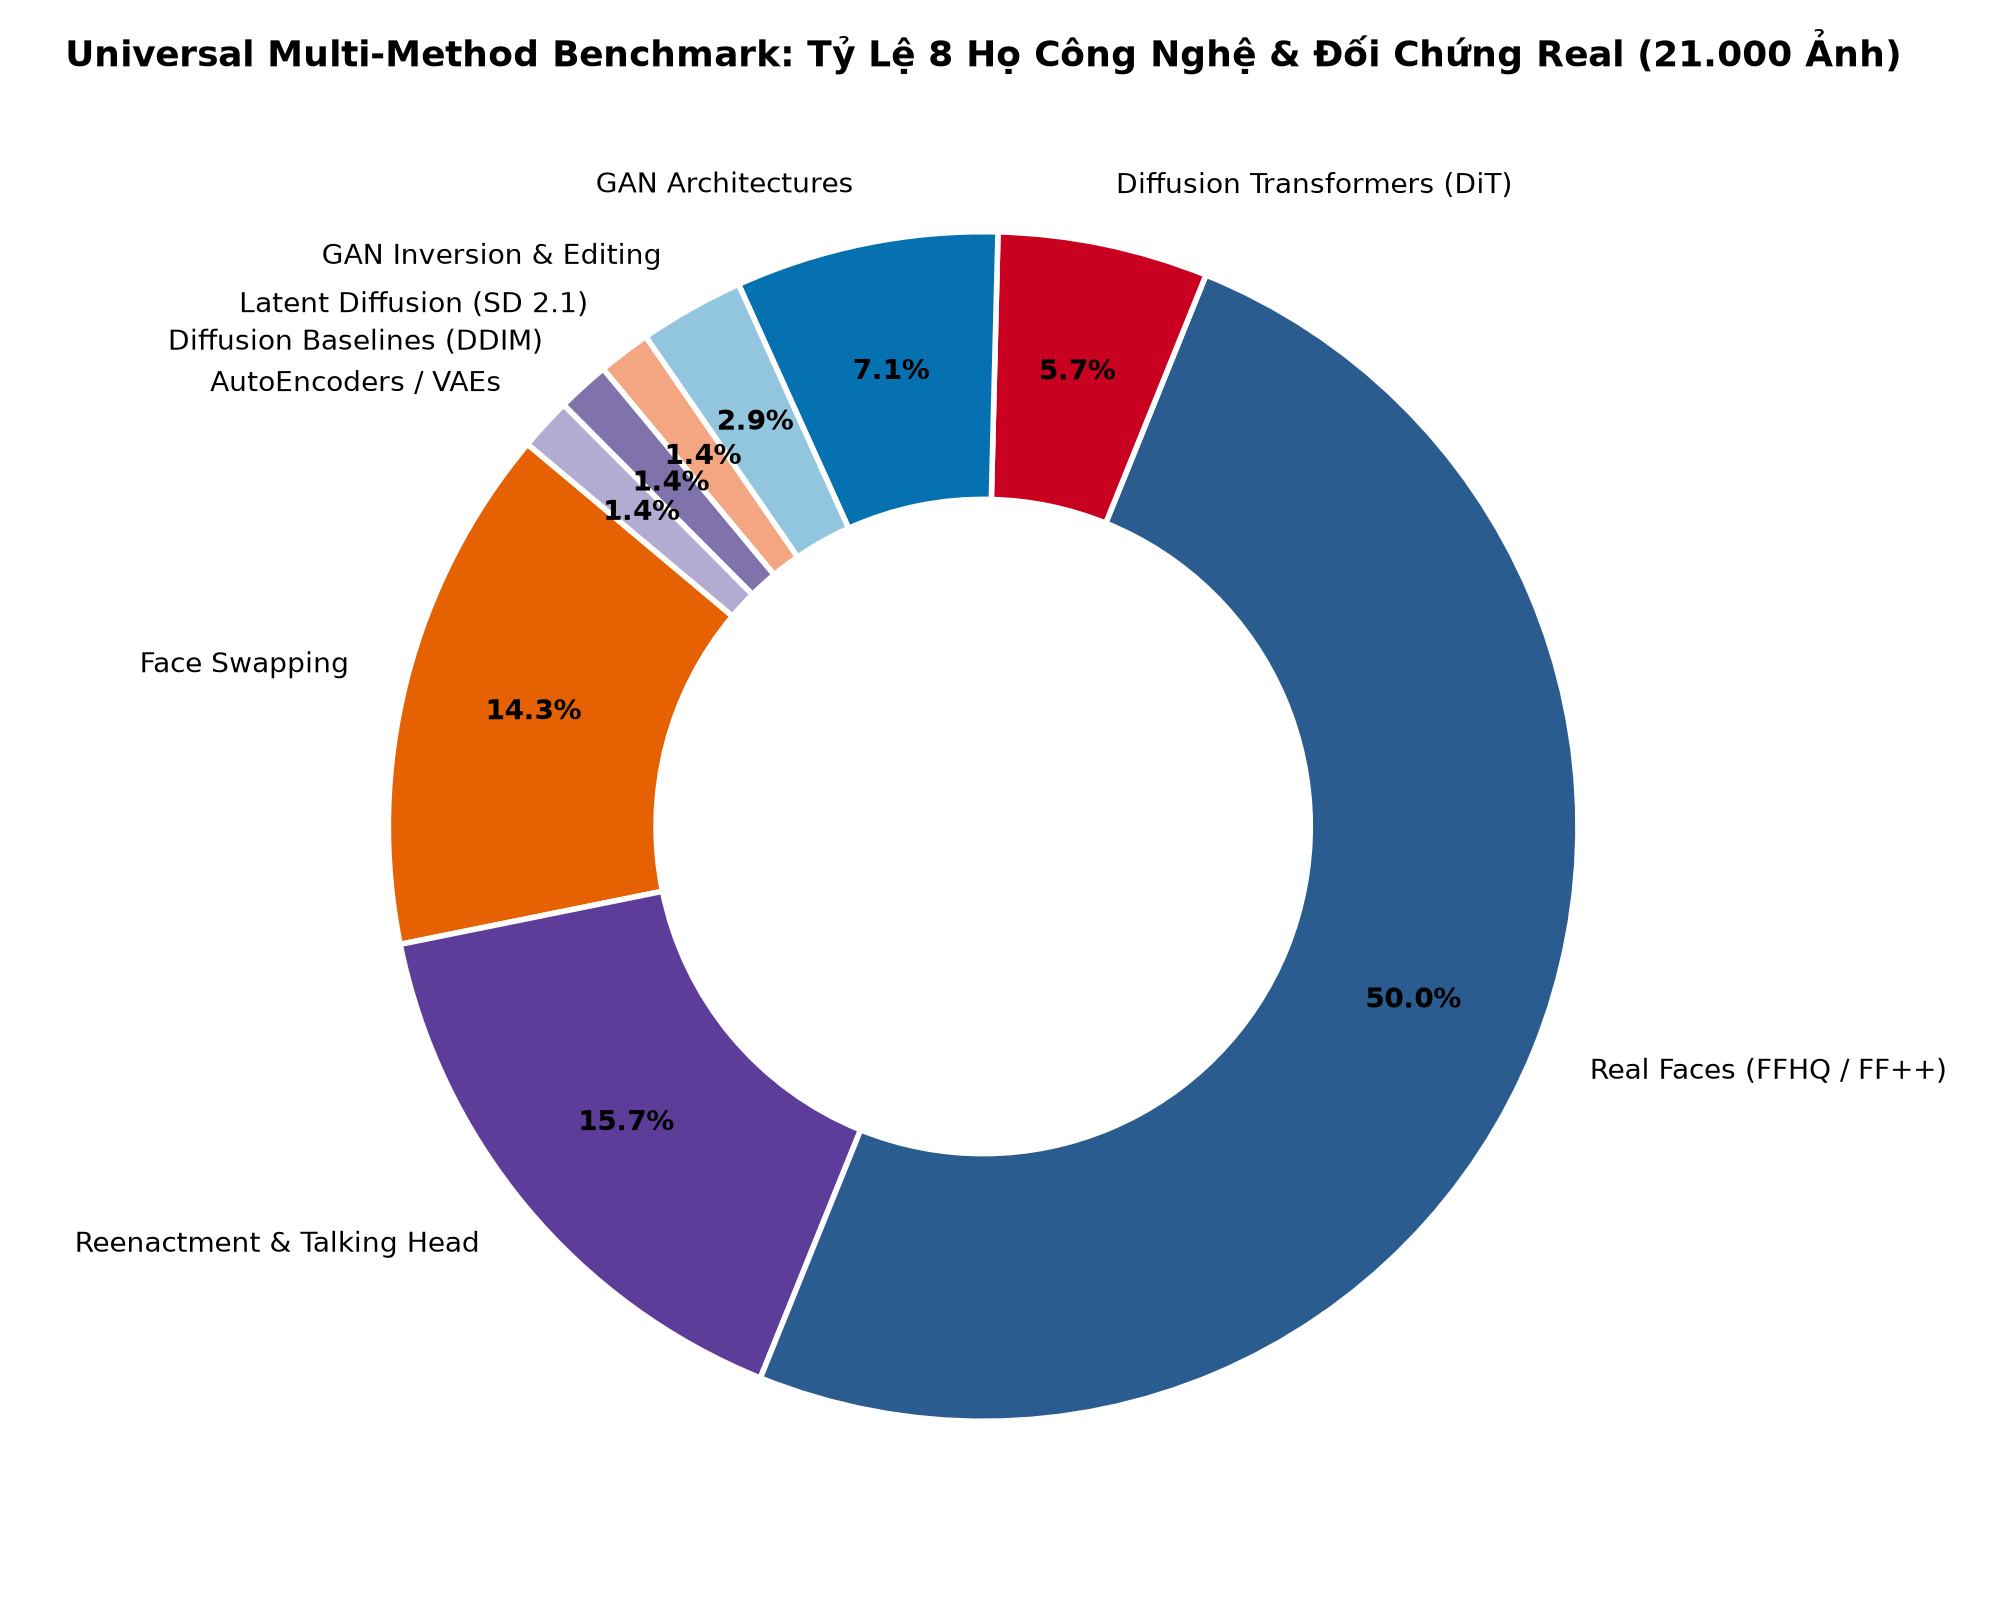

In [3]:
# --- [3. TRỰC QUAN HÓA PHÂN BỐ HỌ CÔNG NGHỆ (DONUT CHART)] ---
from IPython.display import Image as IPImage, display
display(IPImage(filename="experiments/eda/figures/universal_method_families.png"))


### 4. Bảng Phân Bố Chuẩn Hóa 35 Phương Pháp Deepfake (Mỗi Phương Pháp Đúng 300 Mẫu)

Biểu đồ phân bố ngang hiển thị đồng đều 35 phương pháp tạo ảnh giả, được tô màu theo từng họ công nghệ tương ứng:


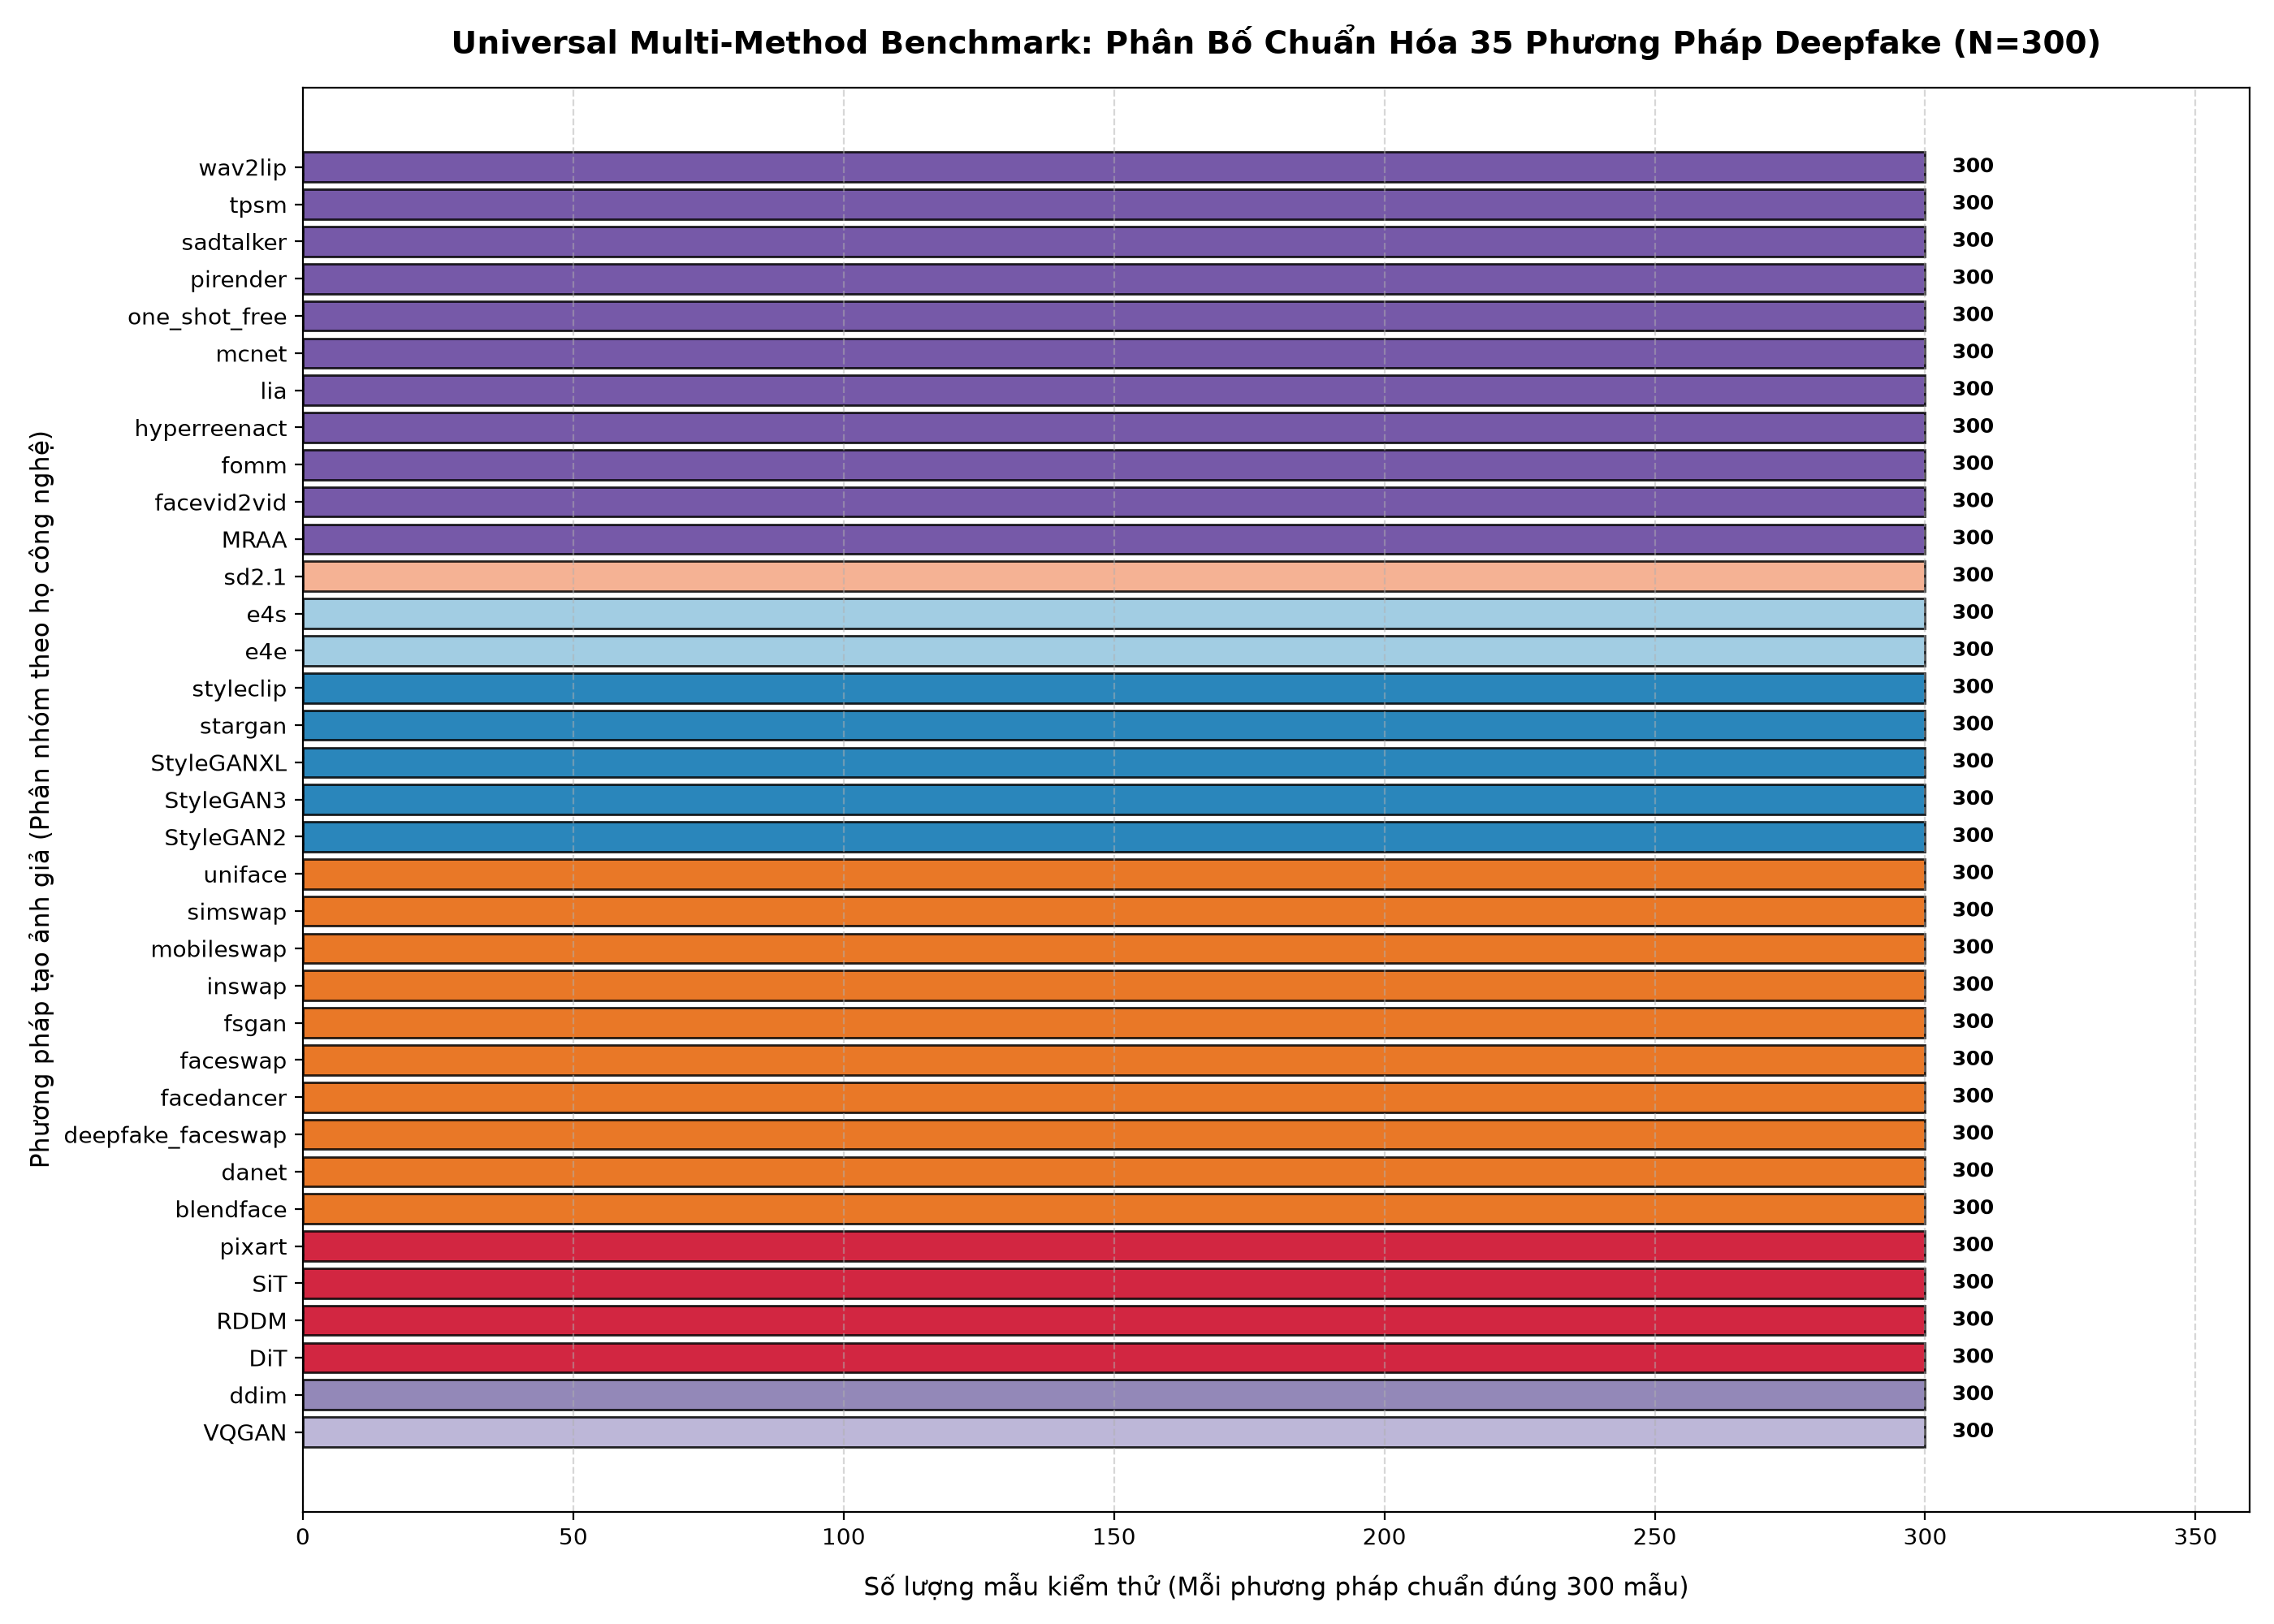

In [4]:
# --- [4. BIỂU ĐỒ PHÂN BỐ 35 PHƯƠNG PHÁP DEEPFAKE ĐỒNG ĐỀU] ---
display(IPImage(filename="experiments/eda/figures/universal_method_distribution.png"))


### 5. Kiểm Toán Chất Lượng Quang Học (Laplacian Sharpness & Contrast)

Đo lường độ sắc nét qua **Phương sai toán tử Laplacian (Laplacian Variance $\sigma^2$)** trên kênh xám và độ tương phản RMS:
$$\text{Sharpness} = \text{Var}\left(\nabla^2 I_{\text{gray}}\right), \quad \text{Contrast} = \text{Std}\left(I_{\text{gray}}\right)$$

- **Dấu vết làm mờ biên hòa trộn (Boundary Feathering)**: Các mô hình hoán đổi mặt (`faceswap`: 53.1, `simswap`: 30.0) và khẩu hình (`wav2lip`: 31.8, `fomm`: 13.4) có độ nét thấp hơn rõ rệt so với ảnh Thật (344.4) do quá trình làm mịn biên ghép nối khuôn mặt.
- **Dấu vết tần số của DiT**: Các mô hình DiT có phổ tần số sắc nét cao (`DiT`: 21.6, `SiT`: 54.0, `RDDM`: 1961.8).


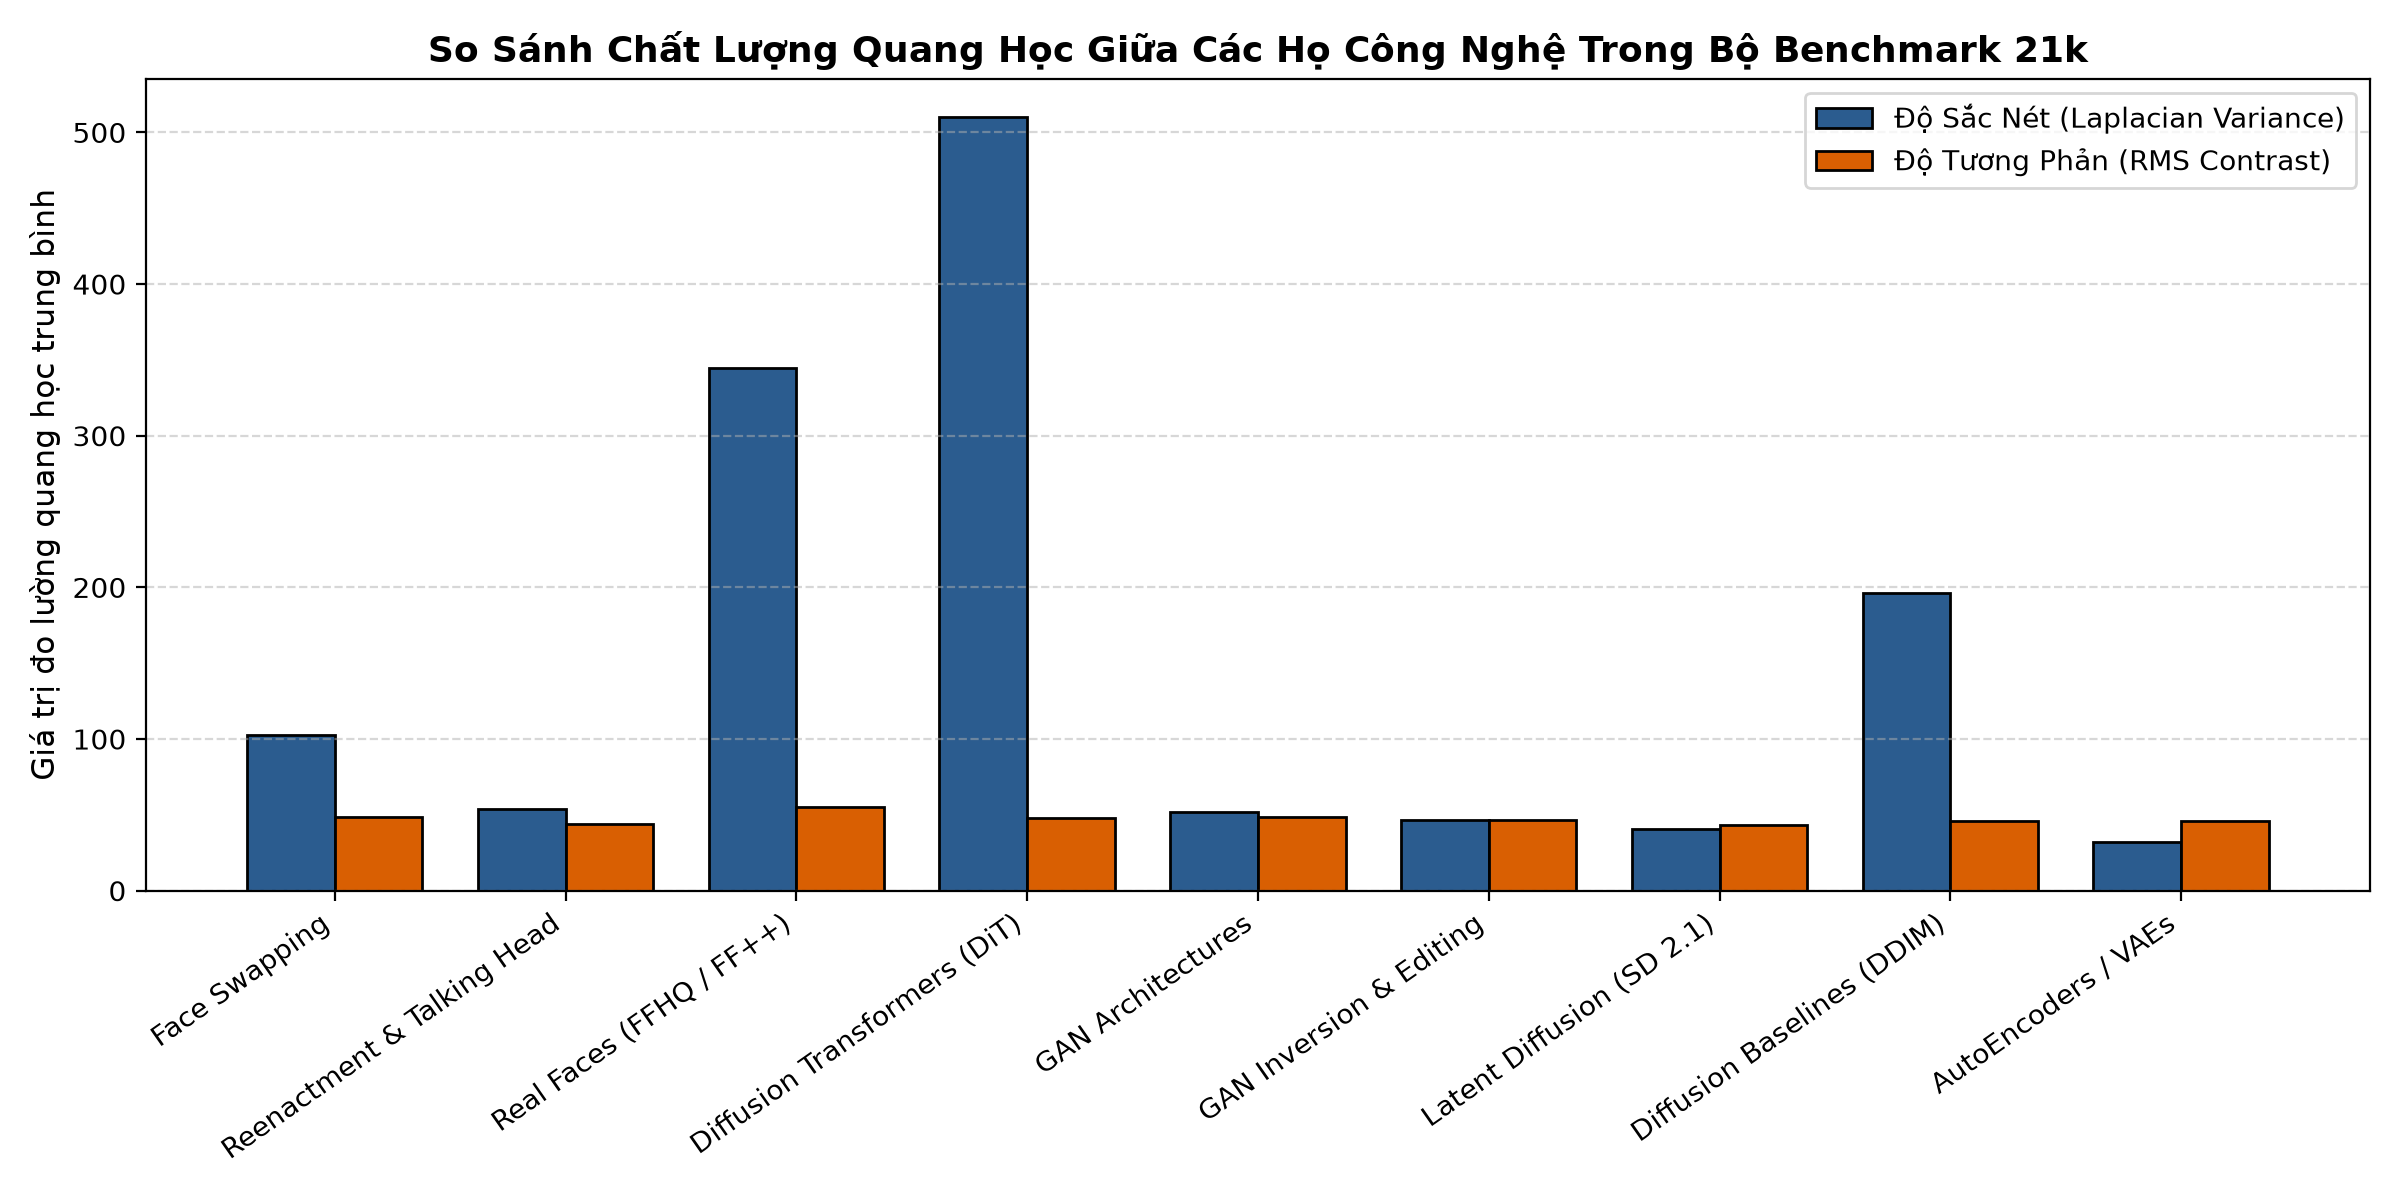

In [5]:
# --- [5. SO SÁNH CHẤT LƯỢNG QUANG HỌC GIỮA CÁC HỌ CÔNG NGHỆ] ---
display(IPImage(filename="experiments/eda/figures/universal_quality_by_family.png"))


### 6. Bộ Sưu Tập Ảnh Mẫu Đại Diện 12 Phương Pháp SOTA

Trực quan hóa trực tiếp các mẫu ảnh đại diện từ 12 nhóm phương pháp tiêu biểu trong bộ kiểm định:


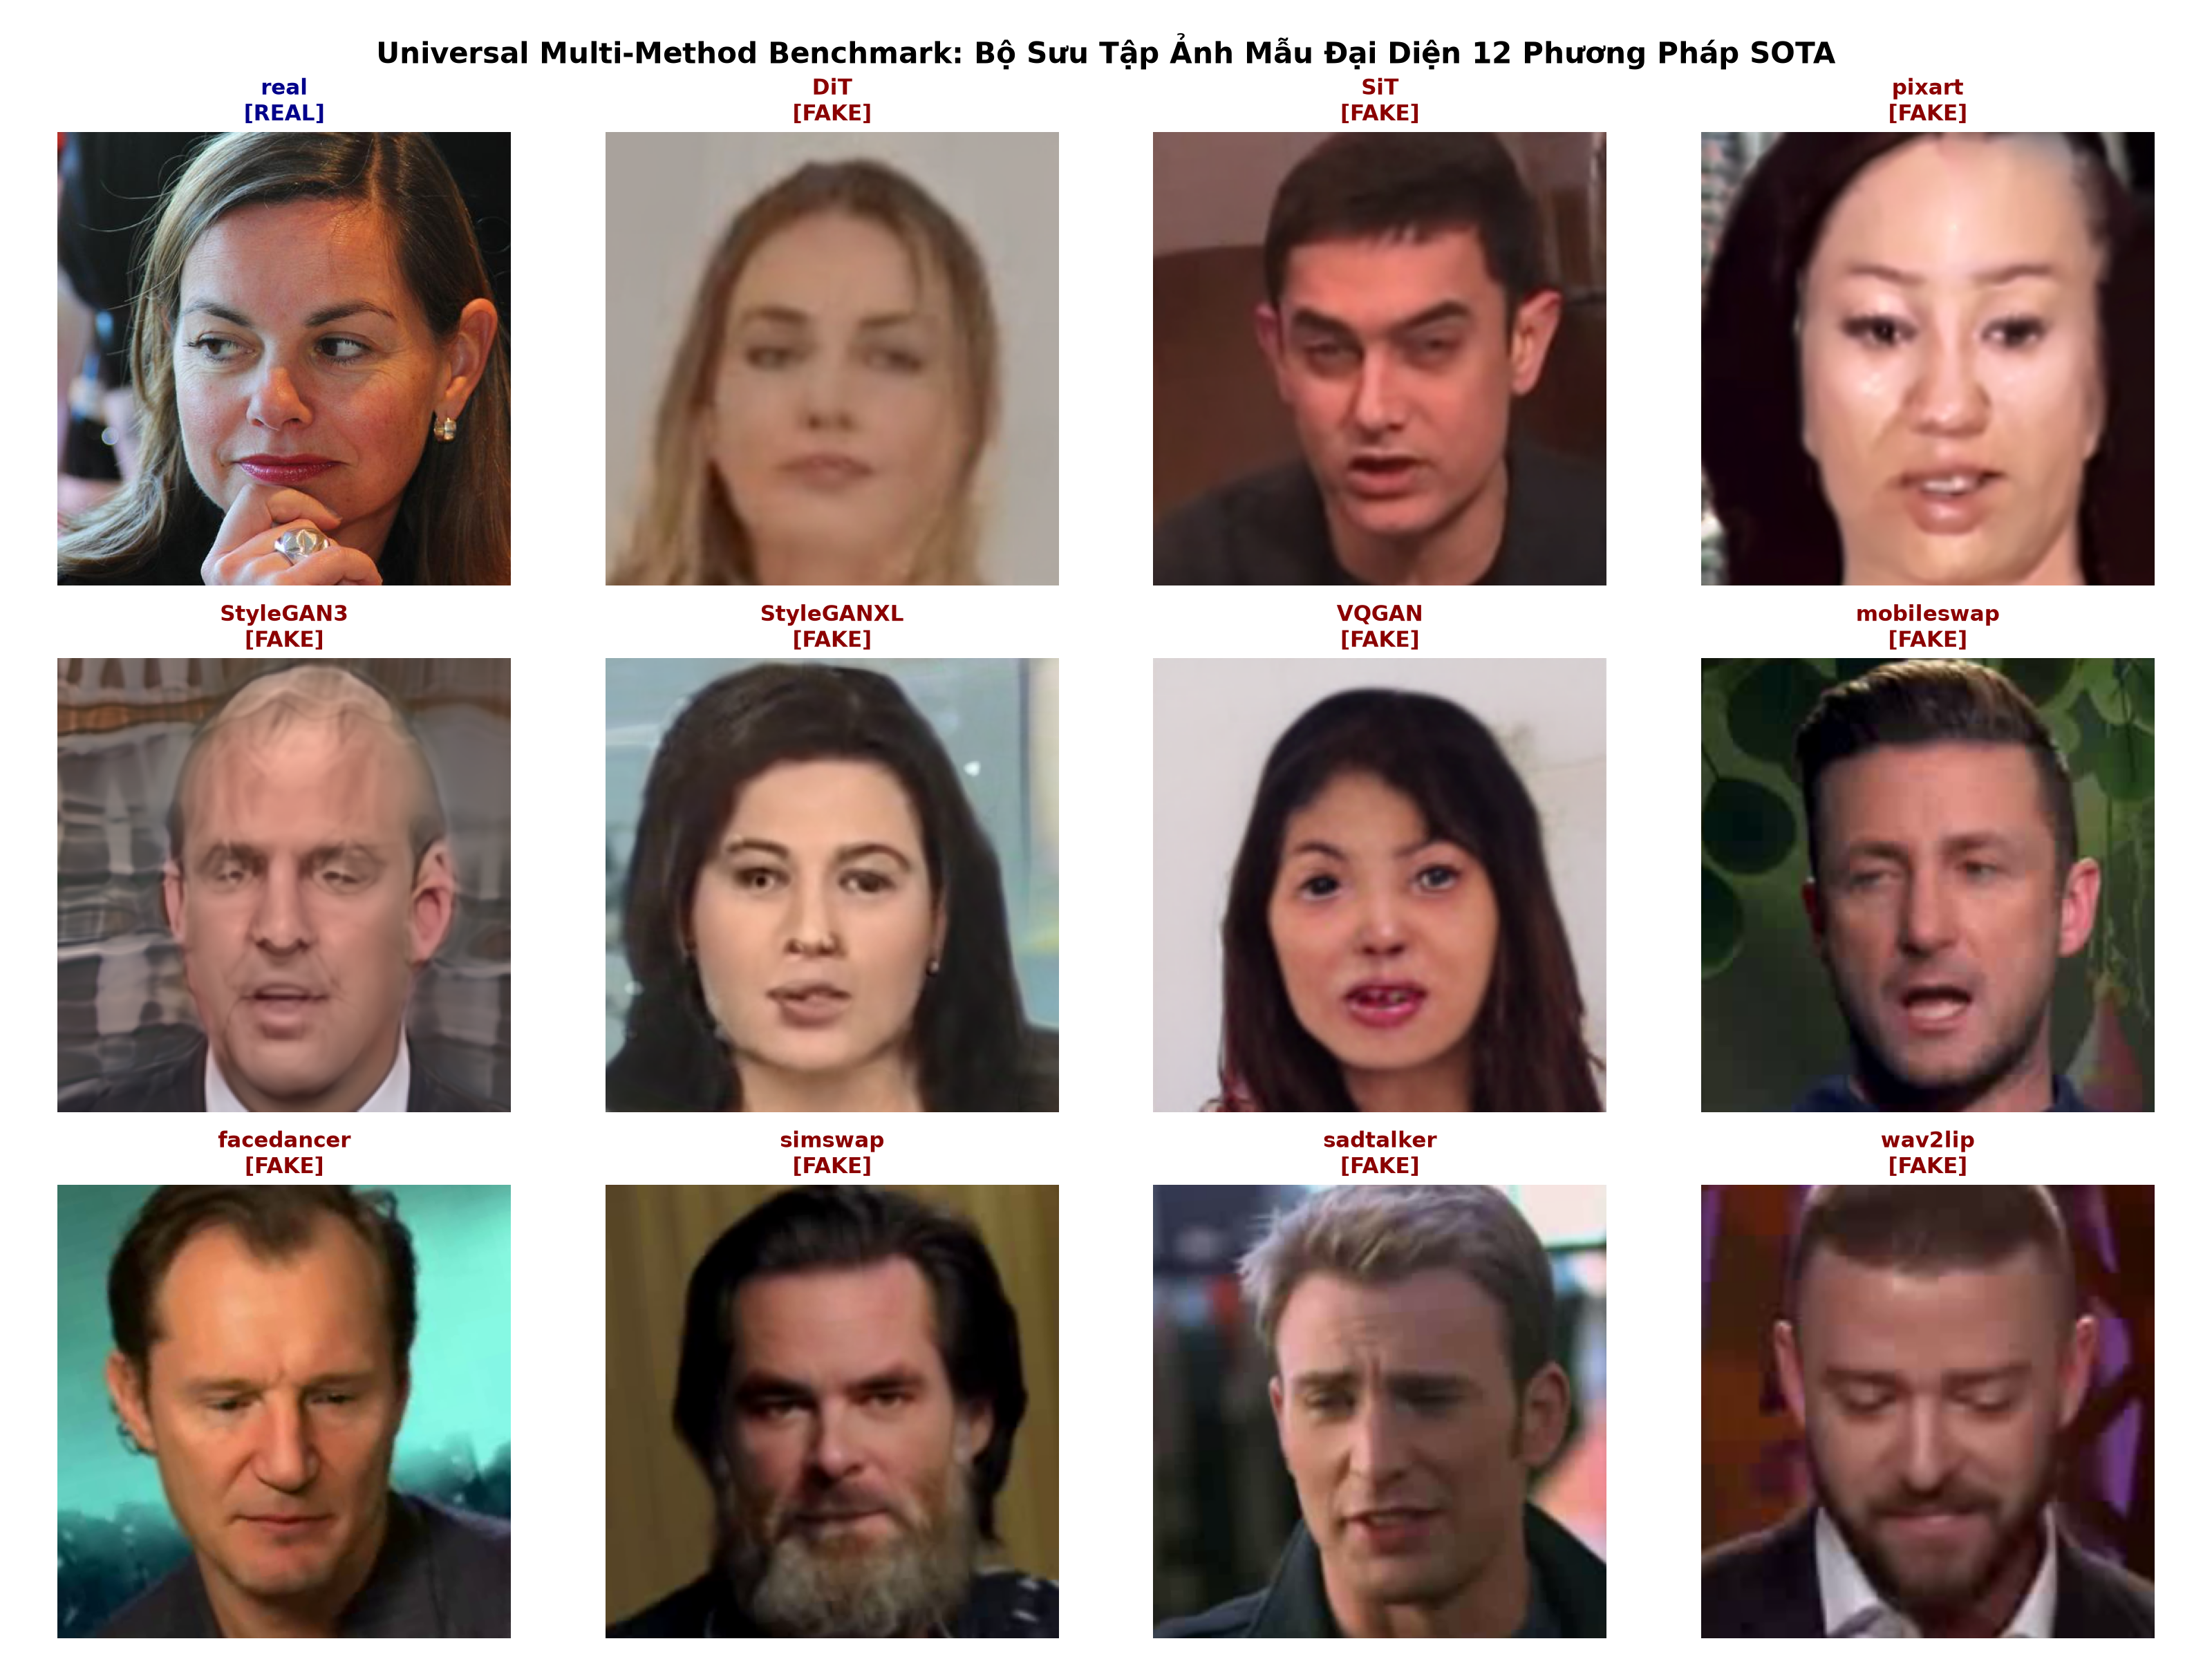

In [6]:
# --- [6. BỘ SƯU TẬP ẢNH MẪU ĐẠI DIỆN 12 PHƯƠNG PHÁP SOTA] ---
display(IPImage(filename="experiments/eda/figures/universal_representative_gallery.png"))


### 7. Nhật Ký Chọn Lọc Dữ Liệu & Loại Trừ Dị Thường (Curation & Pruning Audit)

Bảng tổng kết lý do khoa học của việc sàng lọc từ bộ sưu tập thô sang tập Golden 21k chuẩn hóa:

| Phương Pháp Bị Loại Trừ | Số Mẫu Thô | Họ Công Nghệ | Lý Do Khoa Học Bắt Buộc Loại Bỏ |
| :--- | :---: | :--- | :--- |
| **`heygen`** | 11 | Commercial GenAI | **Vi phạm kích thước mẫu tối thiểu ($N=11 < 30$)**: Sai số 1 mẫu làm lệch 10% Accuracy/Recall. Không có ý nghĩa thống kê. |
| **`deepfacelab`** | 25 | Face Swapping | **Không đủ độ tin cậy thống kê ($N=25 < 30$)**: Phương sai quá lớn, không đại diện cho công cụ DeepFaceLab. |
| **`MidJourney`** | 187 | Commercial GenAI | **Thiếu hụt quota chuẩn (hụt 113 mẫu)**: Làm mất tính đồng đều của trọng số $1/35$ trên mỗi phương pháp. |

> **Lưu ý về hình học khuôn mặt (`deepfake_faceswap`)**:
> - Phương pháp `deepfake_faceswap` có kích thước crop nguyên bản từ CelebA ($178 \times 218$, tỷ lệ $0.82$).
> - Khi nạp vào backbone DINOv2 (đòi hỏi ảnh vuông $224 \times 224$), hệ thống áp dụng phép biến đổi `CenterCropSquare(178, 178)` trước khi resize để chống hiện tượng mặt bị bè ngang méo hình học.


In [7]:
# --- [8. KIỂM TOÁN TÍNH ĐỒNG NHẤT VỀ KÍCH THƯỚC VÀ ĐỘ PHÂN GIẢI] ---
tbl_res_path = Path("experiments/eda/tables/universal_resolution_summary.csv")
if tbl_res_path.exists():
    with open(tbl_res_path, "r", encoding="utf-8") as f:
        res_rows = list(csv.DictReader(f))
    print("=== BẢNG PHÂN BỐ ĐỘ PHÂN GIẢI TRONG TẬP BENCHMARK 21K ===")
    for r in res_rows:
        print(f"[*] Phân giải {r['Resolution (W x H)']:12s}: {r['Sampled Count']:>4s} mẫu ({r['Sampled Percentage']:>6s}) | Aspect Ratio = {r['Aspect Ratio']}")


=== BẢNG PHÂN BỐ ĐỘ PHÂN GIẢI TRONG TẬP BENCHMARK 21K ===
[*] Phân giải 256x256     :  706 mẫu (79.77%) | Aspect Ratio = 1.00
[*] Phân giải 1024x1024   :  100 mẫu (11.30%) | Aspect Ratio = 1.00
[*] Phân giải 512x512     :   28 mẫu ( 3.16%) | Aspect Ratio = 1.00
[*] Phân giải 259x259     :   26 mẫu ( 2.94%) | Aspect Ratio = 1.00
[*] Phân giải 178x218     :   25 mẫu ( 2.82%) | Aspect Ratio = 0.82


### 9. Công Cụ Tương Tác: Khám Phá Mẫu Ảnh Bất Kỳ Theo Phương Pháp (Interactive Sample Inspector)

Sử dụng hàm dưới đây để hiển thị trực quan và đo lường quang học (Laplacian, kích thước, histogram) của bất kỳ phương pháp nào trong 35 phương pháp benchmark:


In [8]:
# --- [9. HÀM TƯƠNG TÁC: XEM ẢNH & ĐO LƯỜNG QUANG HỌC CHI TIẾT] ---
def inspect_method_sample(method_name: str = "DiT"):
    base_img_dir = Path("data/benchmarks/universal_deepfake_benchmark/test_images")
    samples = [r for r in rows if r["method"] == method_name]
    if not samples:
        print(f"[!] Không tìm thấy mẫu cho phương pháp: {method_name}")
        return
    
    sample = samples[0]
    rel_path = sample["path"].lstrip("/")
    full_p = base_img_dir / rel_path
    
    if not full_p.exists():
        print(f"[!] File ảnh không tồn tại: {full_p}")
        return
    
    im = Image.open(full_p).convert("RGB")
    arr = np.array(im)
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    lap_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5))
    ax1.imshow(im)
    ax1.set_title(f"Phương pháp: {method_name}\nNhãn: {'FAKE (1)' if sample['label']=='1' else 'REAL (0)'}\nKích thước: {im.size}", fontsize=11, fontweight="bold")
    ax1.axis("off")
    
    ax2.hist(gray.ravel(), bins=50, color="#2b5c8f", alpha=0.75, edgecolor="black")
    ax2.set_title(f"Histogram Cường Độ Xám\nĐộ sắc nét (Laplacian Var): {lap_var:.1f}", fontsize=11, fontweight="bold")
    ax2.set_xlabel("Pixel Value [0 - 255]")
    ax2.set_ylabel("Tần suất")
    ax2.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

# Trực quan hóa mẫu ảnh của phương pháp DiT
inspect_method_sample("DiT")


Đang hiển thị mẫu đại diện cho phương pháp DiT...
